# CS 363M Final Project
Luke Henderson (ldh2674)  
add names

## Introduction

Parkinson's disease is a progressive neurodegenerative disorder of the central nervous system that primarily affects movement. It affects approximately 1 million Americans, with common symptoms including tremors, stiffness, and slowed movement. Although there is no cure, medications and deep brain stimulation can manage symptoms. The disease is not typically directly fatal, but complications can be life-threatening. Early diagnosis allows for earlier treatment and improved quality of life.

Clinicians assess disease severity with the Unified Parkinson's Disease Rating Scale. Motor UPDRS measures motor symptoms, and total UPDRS measures overall severity, including motor and non-motor symptoms. Higher scores indicate more severe symptoms. This project predicts total UPDRS from voice measurements so that changes in disease severity can be monitored remotely.

## Dataset Description

The Parkinson's Telemonitoring Dataset contains 5,875 voice recordings from 42 patients with early-stage Parkinson's disease, collected over a six-month period. Developed by researchers at the University of Oxford in collaboration with 10 U.S. medical centers and Intel, the dataset explores how changes in speech can be used to monitor Parkinson's disease progression remotely.

Each recording contains 16 biomedical voice measurements, along with patient demographics, time since enrollment, Motor_UPDRS, and Total_UPDRS. The prediction target is total UPDRS. It is the broader severity score because it includes motor and non-motor symptoms. Motor UPDRS remains in the dataset for validity checks and is excluded from the predictors.

The features of the dataset are as follows: 
- Subject: Integer that uniquely identifies each subject  
- Age: Subject age  
- Sex: Subject gender ‘0’ - male, ‘1’ - female  
- Test_time: Time since recruitment into the trial. The integer part is the number of days since recruitment  
- Motor_UPDRS: Clinician’s motor UPDRS score, linearly interpolated  
- Total_UPDRS: Clinician’s total UPDRS score, linearly interpolated  
- Jitter (%), Jitter(Abs), Jitter. RAP, Jitter. PPQ5, Jitter. DDP: Several measures of variation in fundamental frequency (Frequency parameters)  
- Shimmer, Shimmer (dB), Shimmer. APQ3, Shimmer. APQ5, Shimmer. APQ11, Shimmer. DDA: Several measures of variation in amplitude (Amplitude parameters)  
- NHR, HNR: Two measures of ratio of noise to tonal components in the voice  
- RPDE: A nonlinear dynamical complexity measure  
- DFA: Signal fractal scaling exponent  
- PPE: A nonlinear measure of fundamental frequency variation  
  
These voice measurements capture variations in pitch, loudness, noise, and vocal stability, which can be affected by Parkinson's disease. By analyzing patterns in these features, we aim to develop models that accurately predict total UPDRS and support noninvasive, remote monitoring of disease severity and progression.

## Data Prep

### Check for missing, infinite, duplicate, and repeated values

In [75]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/parkinsons_updrs.csv")
repeated_patient_times = df.duplicated(subset=["subject#", "test_time"])

# Check for missing values, infinities, and duplicate rows
print("Missing values:", df.isna().sum().sum())
print("Infinite values:", np.isinf(df).sum().sum())
print(f"Repeated patient/time pairs: {repeated_patient_times.sum():,}")     # multiple recordings that have the same patient and record time as another row (expected, not a problem)
print("Duplicate rows:", df.duplicated().sum())

df.head()

Missing values: 0
Infinite values: 0
Repeated patient/time pairs: 3,374
Duplicate rows: 0


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


The dataset contains no missing values, infinite values, or exact duplicate rows, so no cleaning was necessary. There are 3,374 repeated patient/time pairs, which is expected since patients can have multiple voice recordings at the same recorded time.

### Invalid values check

In [76]:
# Check for invalid or inconsistent values
print("Invalid ages:", ((df["age"] <= 0) | (df["age"] > 120)).sum())
print("Invalid sex values:", (~df["sex"].isin([0, 1])).sum())

print("Negative UPDRS scores:",
      ((df["motor_UPDRS"] < 0) | (df["total_UPDRS"] < 0)).sum())

print("Total UPDRS below motor UPDRS:",
      (df["total_UPDRS"] < df["motor_UPDRS"]).sum())

print("Negative test times:", (df["test_time"] < 0).sum())

Invalid ages: 0
Invalid sex values: 0
Negative UPDRS scores: 0
Total UPDRS below motor UPDRS: 0
Negative test times: 12



All ages, sex values, and UPDRS scores passed the validity checks. There were 12 recordings with negative test times, which may represent measurements taken before the enrollment reference date. Since these are not necessarily errors, we decided to keep them.

### Inspect outliers

In [77]:
continuous = df.drop(columns=["subject#", "sex"])

# Uses Tukeys Fences to detect outliers
q1 = continuous.quantile(0.25)
q3 = continuous.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_flags = (continuous < lower) | (continuous > upper)

outlier_counts = outlier_flags.sum()
outlier_report = pd.DataFrame({
    "lower_fence": lower,
    "upper_fence": upper,
    "outlier_count": outlier_counts,
    "outlier_percent": (outlier_flags.mean() * 100).round(2),
}).sort_values("outlier_count", ascending=False)

display(outlier_report)
print(f"Rows with at least one outlier: {outlier_flags.any(axis=1).sum():,} (all retained)")

,lower_fence,upper_fence,outlier_count,outlier_percent
NHR,-0.019807,0.062225,436,7.42
Jitter:PPQ5,-0.000640,0.005920,425,7.23
Jitter:RAP,-0.000985,0.005855,414,7.05
Jitter:DDP,-0.002980,0.017580,413,7.03
Jitter(%),-0.001250,0.011630,398,6.77
Jitter(Abs),-0.000024,0.000100,366,6.23
Shimmer,-0.011825,0.070695,333,5.67
Shimmer(dB),-0.110000,0.650000,332,5.65
Shimmer:APQ3,-0.007663,0.037518,332,5.65
Shimmer:DDA,-0.023027,0.112592,331,5.63


Rows with at least one outlier: 931 (all retained)


Using Tukey's fences (1.5 × IQR), 931 recordings were flagged as having at least one outlier. Most outliers occurred in the NHR, Jitter, and Shimmer measurements, with roughly 5–7% of values flagged for several of these features. Since extreme voice measurements could reflect genuine differences in Parkinson's symptoms, I decided not to remove any observations.

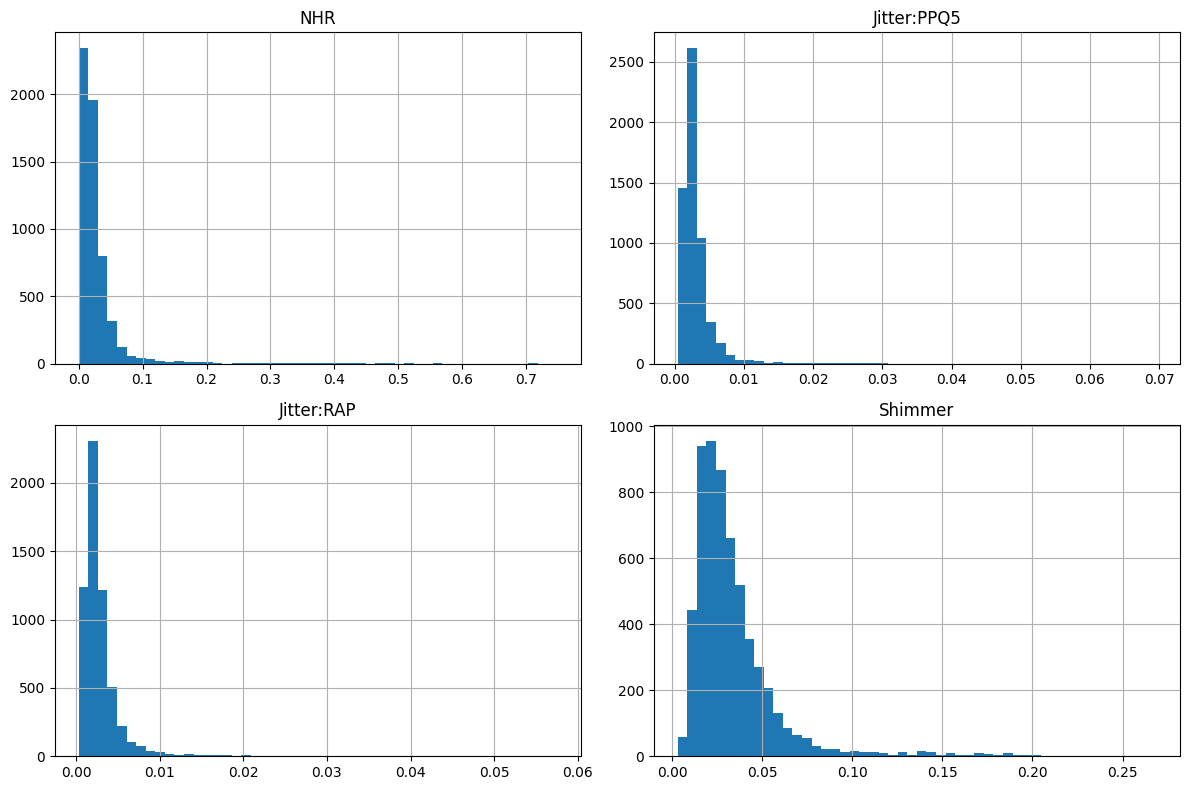

In [78]:
import matplotlib.pyplot as plt

features = ["NHR", "Jitter:PPQ5", "Jitter:RAP", "Shimmer"]

df[features].hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

The histograms show that NHR, Jitter, and Shimmer are strongly right-skewed, with most measurements concentrated at lower values and a relatively small number extending much higher. This explains why the IQR method identified so many outliers. The extreme values appear to be part of long-tailed distributions rather than obvious data errors, so I will retain them for modeling and consider transformations if needed.

In [79]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(splitter.split(df, groups=df["subject#"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Training recordings:", len(train))
print("Testing recordings:", len(test))
print("Training patients:", train["subject#"].nunique())
print("Testing patients:", test["subject#"].nunique())

Training recordings: 4640
Testing recordings: 1235
Training patients: 33
Testing patients: 9


## Data Exploration

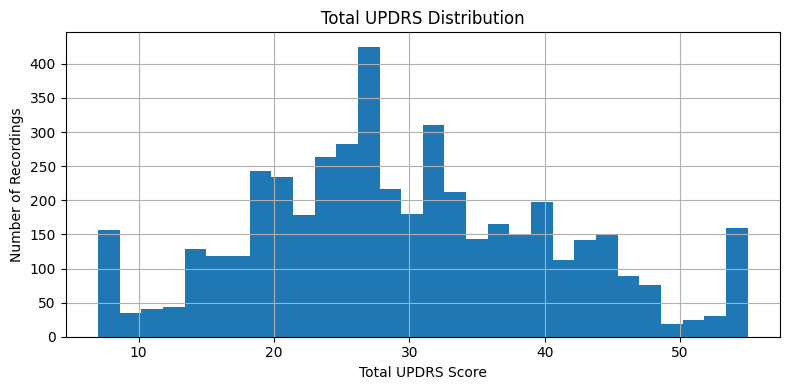

,total_UPDRS
count,4640.000000
mean,29.565597
std,11.022521
min,7.000000
25%,21.715000
50%,28.115500
75%,37.236250
max,54.992000


In [80]:
import matplotlib.pyplot as plt

target = "total_UPDRS"

ax = train[[target]].hist(bins=30, figsize=(8, 4)).flat[0]
ax.set_title("Total UPDRS Distribution")
ax.set_xlabel("Total UPDRS Score")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

display(train[[target]].describe())

The training set contains 4,640 recordings. Total UPDRS ranges from 7.00 to 54.99 and is concentrated around scores of 20–35. The distribution is not strongly skewed, although it has several peaks, which may reflect differences in disease severity between patients. Because the target already covers a broad range of scores, I don't see an immediate need to transform it.

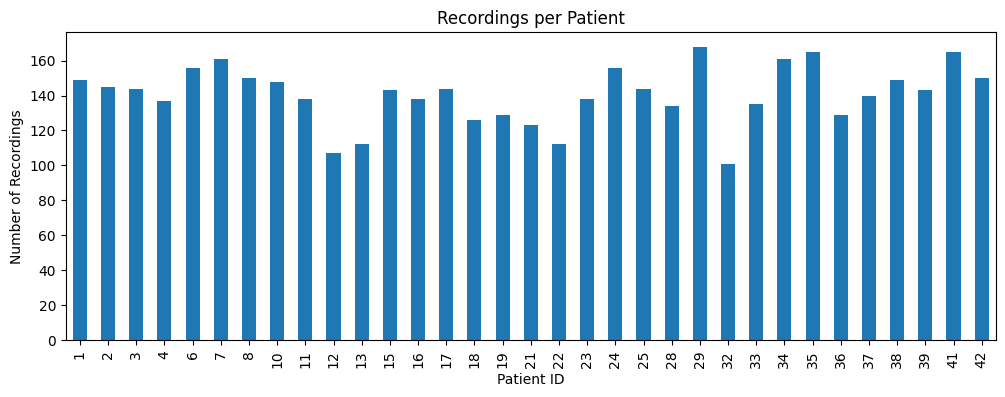

count     33.000000
mean     140.606061
std       16.695694
min      101.000000
25%      134.000000
50%      143.000000
75%      150.000000
max      168.000000
dtype: float64

In [81]:
recordings = train.groupby("subject#").size()

recordings.plot(kind="bar", figsize=(12, 4))
plt.title("Recordings per Patient")
plt.xlabel("Patient ID")
plt.ylabel("Number of Recordings")
plt.show()

display(recordings.describe())

Recording counts range from 101 to 168 and are relatively consistent across patients. Since no patient contributes substantially more recordings than the others, we do not see a need to rebalance or weight the observations by patient.

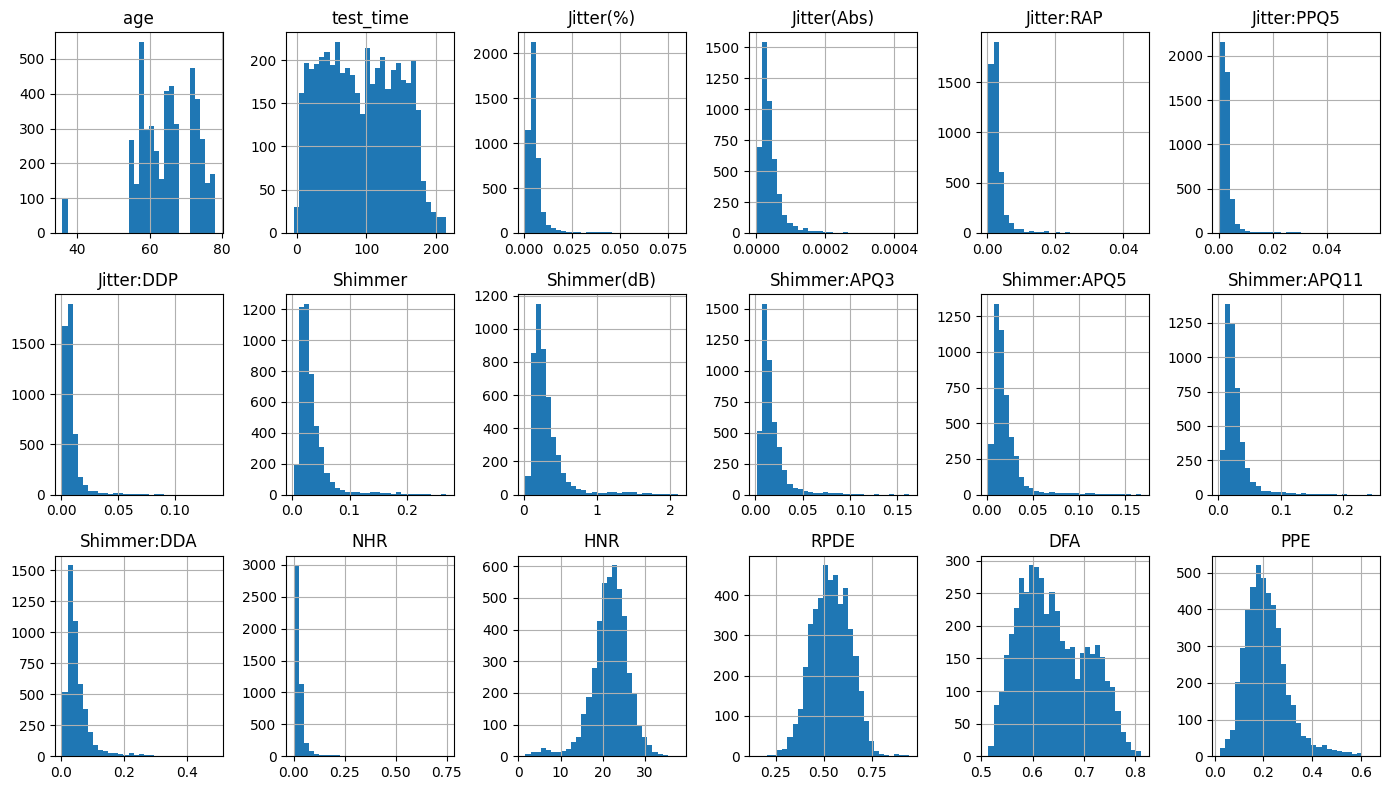

Jitter:PPQ5      6.492170
NHR              6.125149
Jitter:DDP       5.551170
Jitter:RAP       5.551042
Jitter(%)        5.264114
Shimmer:APQ5     3.822463
Jitter(Abs)      3.475975
Shimmer:APQ11    3.434173
Shimmer          3.397594
Shimmer:APQ3     3.205556
Shimmer:DDA      3.205552
Shimmer(dB)      3.181388
PPE              1.102557
DFA              0.330821
test_time        0.086193
RPDE             0.012532
age             -0.781646
HNR             -0.875499
dtype: float64

In [82]:
features = train.drop(
    columns=["subject#", "sex", "motor_UPDRS", "total_UPDRS"]
).columns

train[features].hist(bins=30, figsize=(14, 8), layout=(3, 6))
plt.tight_layout()
plt.show()

display(train[features].skew().sort_values(ascending=False))

Most of the jitter and shimmer measurements, along with NHR, are strongly right-skewed, while HNR and RPDE have more symmetric distributions. The features also vary considerably in scale so we will consider log transformations for highly skewed features and standardization for models sensitive to feature scale such as KNN.

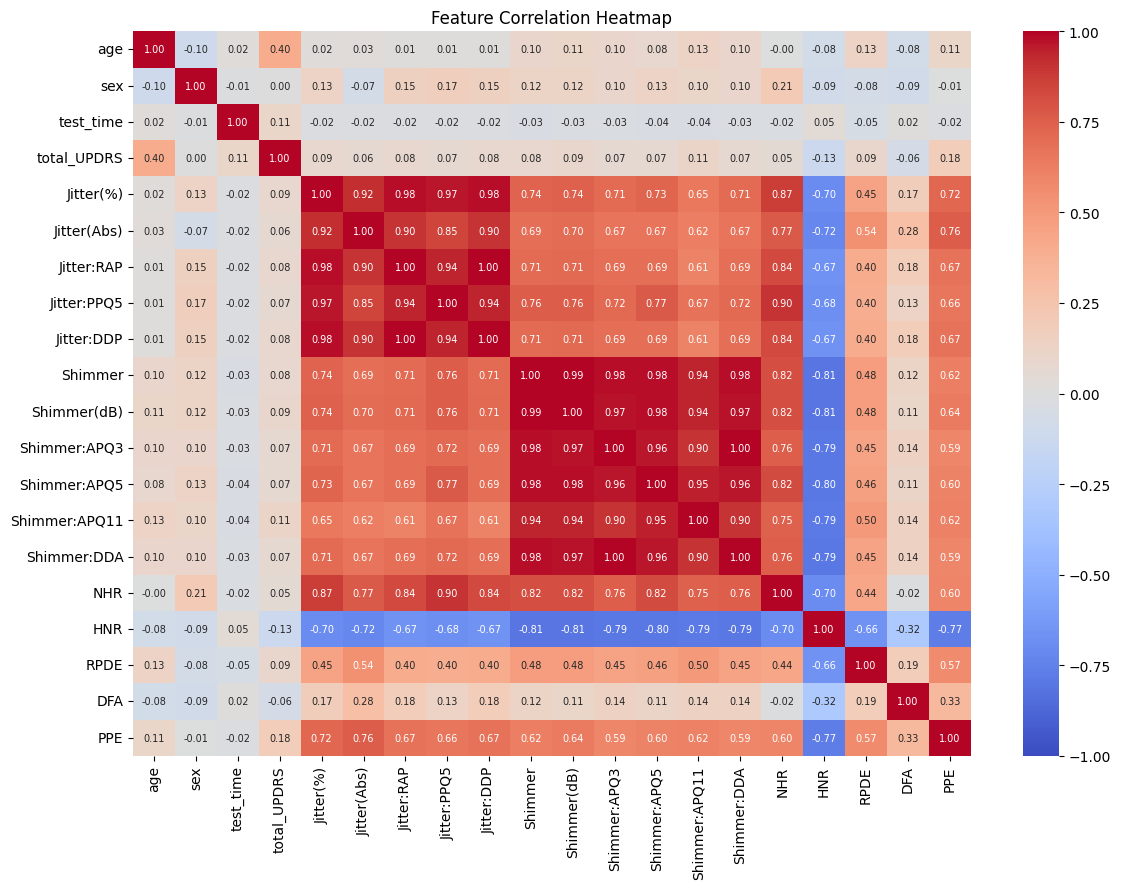

Jitter(%) & Jitter(Abs): 0.9189
Jitter(%) & Jitter:RAP: 0.9843
Jitter(%) & Jitter:PPQ5: 0.9675
Jitter(%) & Jitter:DDP: 0.9843
Jitter(Abs) & Jitter:RAP: 0.9039
Jitter(Abs) & Jitter:DDP: 0.9039
Jitter:RAP & Jitter:PPQ5: 0.9420
Jitter:RAP & Jitter:DDP: 1.0000
Jitter:PPQ5 & Jitter:DDP: 0.9420
Jitter:PPQ5 & NHR: 0.9026
Shimmer & Shimmer(dB): 0.9934
Shimmer & Shimmer:APQ3: 0.9812
Shimmer & Shimmer:APQ5: 0.9841
Shimmer & Shimmer:APQ11: 0.9442
Shimmer & Shimmer:DDA: 0.9812
Shimmer(dB) & Shimmer:APQ3: 0.9711
Shimmer(dB) & Shimmer:APQ5: 0.9768
Shimmer(dB) & Shimmer:APQ11: 0.9450
Shimmer(dB) & Shimmer:DDA: 0.9711
Shimmer:APQ3 & Shimmer:APQ5: 0.9631
Shimmer:APQ3 & Shimmer:APQ11: 0.9024
Shimmer:APQ3 & Shimmer:DDA: 1.0000
Shimmer:APQ5 & Shimmer:APQ11: 0.9478
Shimmer:APQ5 & Shimmer:DDA: 0.9631
Shimmer:APQ11 & Shimmer:DDA: 0.9024


In [83]:
import seaborn as sns

correlation = train.drop(columns=["subject#", "motor_UPDRS"]).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


feature_corr = train[features].corr()

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        corr = feature_corr.iloc[i, j]

        if abs(corr) >= 0.9:
            print(f"{features[i]} & {features[j]}: {corr:.4f}")

Most of the Jitter measurements are highly correlated with each other, and the same is true for Shimmer. We could combine these measurements into one feature for Jitter and one for Shimmer instead of using each measurement individually. Age has the strongest correlation with total UPDRS. Since the voice measurements have weak linear correlations with the target, we also want to test nonlinear models such as decision trees, neural nets, and KNN.

In [84]:
target_corr = correlation.loc[features, "total_UPDRS"]

display(target_corr.sort_values(key=abs, ascending=False))

age              0.401549
PPE              0.182730
HNR             -0.128897
Shimmer:APQ11    0.110255
test_time        0.105407
RPDE             0.089096
Shimmer(dB)      0.086736
Jitter(%)        0.085094
Jitter:DDP       0.079721
Jitter:RAP       0.079706
Shimmer          0.078839
Shimmer:APQ5     0.069368
Jitter:PPQ5      0.067484
Shimmer:DDA      0.065429
Shimmer:APQ3     0.065426
Jitter(Abs)      0.064836
DFA             -0.064137
NHR              0.048002
Name: total_UPDRS, dtype: float64

Age has the strongest correlation with total UPDRS, followed by PPE. Most of the other features have correlations below 0.1 in magnitude. Since no individual feature has a strong linear relationship with the target, we are going to see how well these features work together and whether nonlinear models perform better.

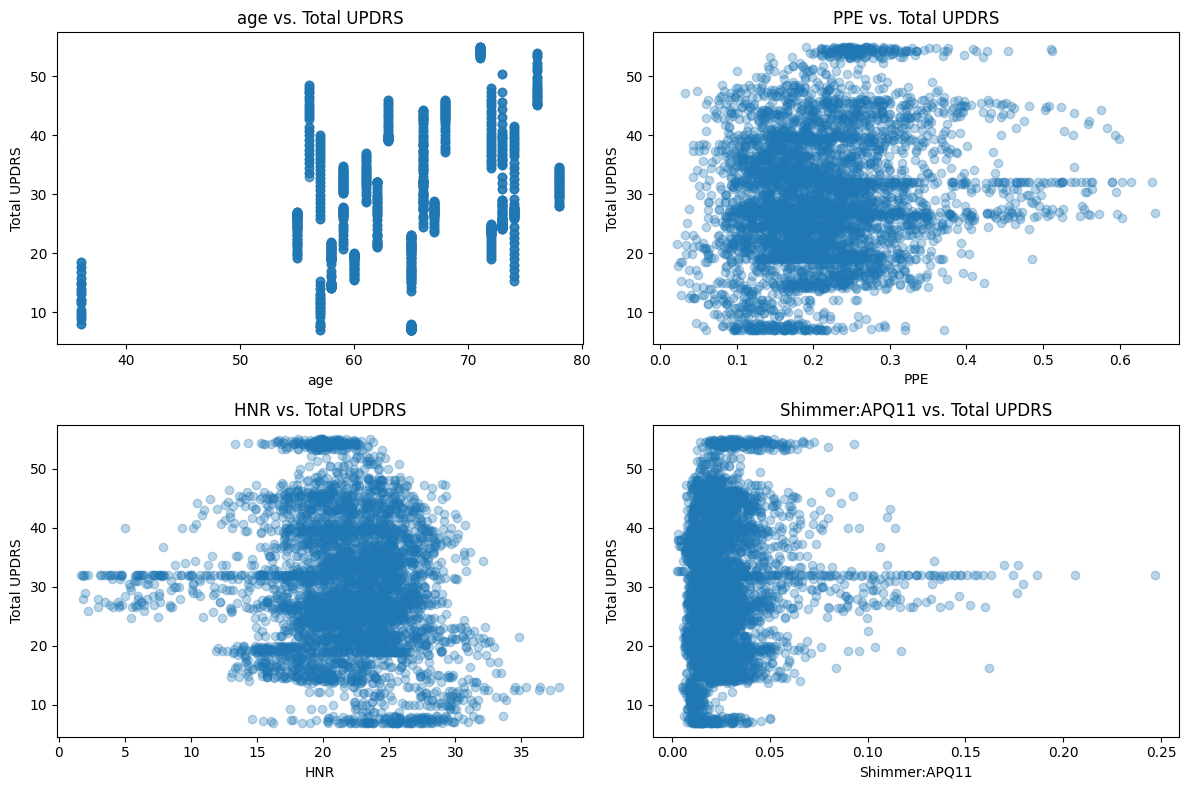

In [85]:
selected = target_corr.abs().nlargest(4).index

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected, axes.flat):
    ax.scatter(train[feature], train["total_UPDRS"], alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel("Total UPDRS")
    ax.set_title(f"{feature} vs. Total UPDRS")

plt.tight_layout()
plt.show()

Age shows the clearest relationship with total UPDRS, with older patients generally having higher scores. The other three features are much more scattered and do not show clear linear trends. This makes it difficult to predict UPDRS from any single voice measurement, so again, this leads us to test how well the features work together in both linear and nonlinear models.

## Feature Engineering

In [86]:
X_train = train.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"])
X_test = test.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"])

y_train = train["total_UPDRS"].copy()
y_test = test["total_UPDRS"].copy()

In [87]:
from sklearn.preprocessing import StandardScaler

jitter_cols = [col for col in X_train.columns if col.startswith("Jitter")]
shimmer_cols = [col for col in X_train.columns if col.startswith("Shimmer")]

jitter_scaler = StandardScaler()
shimmer_scaler = StandardScaler()

X_train["Jitter_combined"] = jitter_scaler.fit_transform(
    X_train[jitter_cols]
).mean(axis=1)

X_test["Jitter_combined"] = jitter_scaler.transform(
    X_test[jitter_cols]
).mean(axis=1)

X_train["Shimmer_combined"] = shimmer_scaler.fit_transform(
    X_train[shimmer_cols]
).mean(axis=1)

X_test["Shimmer_combined"] = shimmer_scaler.transform(
    X_test[shimmer_cols]
).mean(axis=1)

X_train.head()

,age,sex,test_time,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),...,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE,Jitter_combined,Shimmer_combined
0,72,0,5.6431,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,0.230,...,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006,0.123503,-0.334797
1,72,0,12.6660,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,0.179,...,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810,-0.563474,-0.532591
2,72,0,19.6810,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,0.181,...,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014,-0.320535,-0.657220
3,72,0,25.6470,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,0.327,...,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277,-0.280612,-0.343086
4,72,0,33.6420,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,0.176,...,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361,-0.594472,-0.634276


Since the Jitter measurements are highly correlated with each other and the same is true for Shimmer, we created two new features by standardizing and averaging the measurements within each group. This allows us to represent both vocal characteristics with fewer features, reducing the dimensionss.

In [88]:
X_train_reduced = X_train.drop(columns=jitter_cols + shimmer_cols)
X_test_reduced = X_test.drop(columns=jitter_cols + shimmer_cols)

print("Full feature count:", X_train.shape[1])
print("Reduced feature count:", X_train_reduced.shape[1])

Full feature count: 21
Reduced feature count: 10


### Skewing test  
We tested a log transformation on the right-skewed voice measurements, but it had little effect on their distributions. For example, the skewness of NHR only decreased from 6.13 to 5.45. Since most of these measurements are already very small, adding 1 before taking the logarithm results in little change. We decided to keep the original values and remove this transformation step for now.

## Modeling: Predicting total_UPDRS

In [89]:
import sklearn.metrics as metrics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV
from sklearn.linear_model import LinearRegression

In [90]:
X_train = X_train_reduced.copy()
X_test = X_test_reduced.copy()

groups_train = train.loc[X_train.index, "subject#"].copy()

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert X_train.index.equals(groups_train.index)
assert X_train.columns.equals(X_test.columns)
assert set(groups_train).isdisjoint(test["subject#"])

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training patients:", groups_train.nunique())
print("Testing patients:", test["subject#"].nunique())
print("Features:", list(X_train.columns))

Training features: (4640, 10)
Testing features: (1235, 10)
Training patients: 33
Testing patients: 9
Features: ['age', 'sex', 'test_time', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE', 'Jitter_combined', 'Shimmer_combined']


# Modeling

## Linear Regression on all features

In [91]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_predicted = linear_model.predict(X_train)
print(f"The MAE is {metrics.mean_absolute_error(y_train, y_predicted)}")
print(f"The RMSE is {metrics.root_mean_squared_error(y_train, y_predicted)}")
print(f"The R^2 is {metrics.r2_score(y_train, y_predicted)}")

The MAE is 8.177354162255202
The RMSE is 9.773534691268264
The R^2 is 0.2136153168554289


## Cross Validation Setup
Every model uses the same 5 folds from GroupKFold on the training set, with groups=groups_train so a patient's recordings are never split between a training fold and a validation fold. GroupKFold has no randomness, so it gives the same folds every time it is used.

In [92]:
gkf = GroupKFold(n_splits=5)

# show which patients are in each validation fold
for i, (fold_train, fold_val) in enumerate(gkf.split(X_train, y_train, groups_train)):
    print(f"Fold {i}: {len(fold_val)} validation records, patients {sorted(groups_train.iloc[fold_val].unique().tolist())}")

Fold 0: 869 validation records, patients [1, 2, 15, 19, 29, 33]
Fold 1: 967 validation records, patients [16, 18, 23, 32, 38, 41, 42]
Fold 2: 971 validation records, patients [8, 10, 11, 12, 21, 35, 37]
Fold 3: 868 validation records, patients [3, 6, 7, 25, 28, 36]
Fold 4: 965 validation records, patients [4, 13, 17, 22, 24, 34, 39]


## Forward Feature Selection

We compare five feature groups: features picked by a linear model, features picked by a nonlinear model, features kept by Lasso, voice features + sex + age, and all features (voice + sex + age + test_time).

Both selections use the same loop. Start with no features. At each step, try adding each remaining feature, score it with a scaler + model pipeline on the shared folds, and keep the feature with the lowest CV MAE. A feature is only added if it lowers CV MAE by at least 0.5% compared to the current set. Otherwise we stop.

### Linear Selection

Selection with `LinearRegression`.

In [93]:
selected = []
remaining = list(X_train.columns)
current_mae = None
steps = []

while len(remaining) > 0:
    # try adding each remaining feature and keep the best one
    best_feature = None
    best_mae = None
    for feature in remaining:
        pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
        scores = cross_val_score(pipe, X_train[selected + [feature]], y_train, cv=gkf,
                                 groups=groups_train, scoring="neg_mean_absolute_error")
        mae = -scores.mean()
        if best_mae is None or mae < best_mae:
            best_mae = mae
            best_feature = feature

    # first feature is always added; after that it needs at least 0.5% improvement
    if current_mae is None:
        improvement = None
    else:
        improvement = (current_mae - best_mae) / current_mae * 100
        if improvement < 0.5:
            print(f"Stopping: best next feature was {best_feature} with only {improvement:.2f}% improvement")
            break

    selected.append(best_feature)
    remaining.remove(best_feature)
    current_mae = best_mae
    steps.append({"step": len(selected), "feature added": best_feature,
                  "CV MAE": best_mae, "% improvement": improvement})

print(pd.DataFrame(steps))
linear_features = selected
print(f"Linear selected features: {linear_features}")

Stopping: best next feature was Jitter_combined with only 0.03% improvement
   step feature added    CV MAE  % improvement
0     1           age  8.468314            NaN
1     2           PPE  8.340056       1.514558
Linear selected features: ['age', 'PPE']


### Nonlinear Selection

Same loop, but with `KNeighborsRegressor(n_neighbors=50)` as the model.

In [94]:
from sklearn.neighbors import KNeighborsRegressor

selected = []
remaining = list(X_train.columns)
current_mae = None
steps = []

while len(remaining) > 0:
    # try adding each remaining feature and keep the best one
    best_feature = None
    best_mae = None
    for feature in remaining:
        pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=50))])
        scores = cross_val_score(pipe, X_train[selected + [feature]], y_train, cv=gkf,
                                 groups=groups_train, scoring="neg_mean_absolute_error")
        mae = -scores.mean()
        if best_mae is None or mae < best_mae:
            best_mae = mae
            best_feature = feature

    # first feature is always added; after that it needs at least 0.5% improvement
    if current_mae is None:
        improvement = None
    else:
        improvement = (current_mae - best_mae) / current_mae * 100
        if improvement < 0.5:
            print(f"Stopping: best next feature was {best_feature} with only {improvement:.2f}% improvement")
            break

    selected.append(best_feature)
    remaining.remove(best_feature)
    current_mae = best_mae
    steps.append({"step": len(selected), "feature added": best_feature,
                  "CV MAE": best_mae, "% improvement": improvement})

print(pd.DataFrame(steps))
nonlinear_features = selected
print(f"Nonlinear selected features: {nonlinear_features}")

Stopping: best next feature was test_time with only -0.82% improvement
   step feature added    CV MAE % improvement
0     1           NHR  9.224371          None
Nonlinear selected features: ['NHR']


### Lasso Selection

Lasso shrinks the coefficients of unhelpful features to exactly 0. We tune its penalty `alpha` on all features with the shared folds and keep the features whose coefficient is not 0.

In [95]:
from sklearn.linear_model import Lasso

lasso_pipe = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=10000))])
param_grid = {"lasso__alpha": [0.01, 0.1, 0.5, 1, 2, 5]}
lasso_search = GridSearchCV(lasso_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error")
lasso_search.fit(X_train, y_train, groups=groups_train)
print(lasso_search.best_params_)
print(f"CV MAE: {-lasso_search.best_score_}")

# coefficients of the best Lasso model, one per feature
coefs = pd.Series(lasso_search.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
print(coefs)
lasso_features = list(coefs[coefs != 0].index)
print(f"Lasso selected features: {lasso_features}")

{'lasso__alpha': 1}
CV MAE: 8.49301925116179
age                 3.353662
sex                 0.000000
test_time           0.120467
NHR                 0.000000
HNR                -0.000000
RPDE                0.000000
DFA                -0.000000
PPE                 0.661867
Jitter_combined     0.000000
Shimmer_combined    0.000000
dtype: float64
Lasso selected features: ['age', 'test_time', 'PPE']


### Voice + Sex + Age and All Features

Two fixed groups with no selection. `Voice + sex + age` is the seven retained voice features (including `Jitter_combined` and `Shimmer_combined`) plus `sex` and `age`. `All features` adds `test_time`, so comparing the two shows whether `test_time` helps.

In [96]:
voice_sex_age = [col for col in X_train.columns if col != "test_time"]
all_features = list(X_train.columns)

feature_groups = {
    "Linear selection": linear_features,
    "Nonlinear selection": nonlinear_features,
    "Lasso selection": lasso_features,
    "Voice + sex + age": voice_sex_age,
    "All features": all_features,
}
for group, cols in feature_groups.items():
    print(f"{group} ({len(cols)} features): {cols}")

Linear selection (2 features): ['age', 'PPE']
Nonlinear selection (1 features): ['NHR']
Lasso selection (3 features): ['age', 'test_time', 'PPE']
Voice + sex + age (9 features): ['age', 'sex', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE', 'Jitter_combined', 'Shimmer_combined']
All features (10 features): ['age', 'sex', 'test_time', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE', 'Jitter_combined', 'Shimmer_combined']


## Modeling

Each model is a pipeline of `StandardScaler` + the model, run on each of the five feature groups. For each group we:
1. Score the default (untuned) pipeline with the shared folds.
2. Tune it with `GridSearchCV` on the same folds, using MAE.
3. Score the best pipeline from the grid search.

`evaluate` runs `cross_validate` on the shared folds and returns the average train MAE, CV MAE, CV RMSE, and CV R^2. Every result is saved in `results`. `n_jobs=-1` makes the grid search use all CPU cores so it runs faster.

In [97]:
def evaluate(pipe, X_group):
    results = cross_validate(pipe, X_group, y_train, cv=gkf, groups=groups_train,
                             scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
                             return_train_score=True)
    return {
        "train MAE": -results["train_neg_mean_absolute_error"].mean(),
        "CV MAE": -results["test_neg_mean_absolute_error"].mean(),
        "CV RMSE": -results["test_neg_root_mean_squared_error"].mean(),
        "CV R^2": results["test_r2"].mean(),
    }

results = []

### Mean Baseline

`DummyRegressor` always predicts the mean `total_UPDRS` of the training folds and ignores the features. Every model should beat this.

In [98]:
from sklearn.dummy import DummyRegressor

for group, cols in feature_groups.items():
    mean_pipe = Pipeline([("scaler", StandardScaler()), ("mean", DummyRegressor())])
    mean_result = evaluate(mean_pipe, X_train[cols])

    print(f"{group}: CV MAE {mean_result['CV MAE']:.3f}")
    results.append({"feature group": group, "model": "Mean Baseline", "best params": "none",
                    "untuned CV MAE": mean_result["CV MAE"], **mean_result})

Linear selection: CV MAE 9.069
Nonlinear selection: CV MAE 9.069
Lasso selection: CV MAE 9.069
Voice + sex + age: CV MAE 9.069
All features: CV MAE 9.069


### Linear Regression

Linear regression has no hyperparameters to tune, so the untuned and tuned results are the same.

In [99]:
for group, cols in feature_groups.items():
    lin_pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
    lin_tuned = evaluate(lin_pipe, X_train[cols])

    print(f"{group}: CV MAE {lin_tuned['CV MAE']:.3f}")
    results.append({"feature group": group, "model": "Linear Regression", "best params": "none",
                    "untuned CV MAE": lin_tuned["CV MAE"], **lin_tuned})

Linear selection: CV MAE 8.340
Nonlinear selection: CV MAE 9.198
Lasso selection: CV MAE 8.441
Voice + sex + age: CV MAE 9.013
All features: CV MAE 9.100


### Ridge Regression

Linear regression with an L2 penalty that shrinks all coefficients. Tune the penalty strength `alpha`.

In [100]:
from sklearn.linear_model import Ridge

param_grid = {
    "ridge__alpha": [0.1, 1, 10, 100, 1000, 10000],
}

for group, cols in feature_groups.items():
    ridge_pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
    ridge_untuned = evaluate(ridge_pipe, X_train[cols])

    ridge_search = GridSearchCV(ridge_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    ridge_search.fit(X_train[cols], y_train, groups=groups_train)
    ridge_tuned = evaluate(ridge_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {ridge_untuned['CV MAE']:.3f}, tuned CV MAE {ridge_tuned['CV MAE']:.3f}")
    print(f"    best params: {ridge_search.best_params_}")
    results.append({"feature group": group, "model": "Ridge", "best params": ridge_search.best_params_,
                    "untuned CV MAE": ridge_untuned["CV MAE"], **ridge_tuned})

Linear selection: untuned CV MAE 8.340, tuned CV MAE 8.337
    best params: {'ridge__alpha': 100}
Nonlinear selection: untuned CV MAE 9.198, tuned CV MAE 9.050
    best params: {'ridge__alpha': 10000}
Lasso selection: untuned CV MAE 8.441, tuned CV MAE 8.429
    best params: {'ridge__alpha': 1000}
Voice + sex + age: untuned CV MAE 9.012, tuned CV MAE 8.691
    best params: {'ridge__alpha': 1000}
All features: untuned CV MAE 9.099, tuned CV MAE 8.756
    best params: {'ridge__alpha': 1000}


### Lasso Regression

Linear regression with an L1 penalty that can shrink coefficients to exactly 0. Tune the penalty strength `alpha`.

In [101]:
from sklearn.linear_model import Lasso

param_grid = {
    "lasso__alpha": [0.01, 0.1, 0.5, 1, 2, 5],
}

for group, cols in feature_groups.items():
    lasso_pipe = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=10000))])
    lasso_untuned = evaluate(lasso_pipe, X_train[cols])

    lasso_search = GridSearchCV(lasso_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    lasso_search.fit(X_train[cols], y_train, groups=groups_train)
    lasso_tuned = evaluate(lasso_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {lasso_untuned['CV MAE']:.3f}, tuned CV MAE {lasso_tuned['CV MAE']:.3f}")
    print(f"    best params: {lasso_search.best_params_}")
    results.append({"feature group": group, "model": "Lasso", "best params": lasso_search.best_params_,
                    "untuned CV MAE": lasso_untuned["CV MAE"], **lasso_tuned})

Linear selection: untuned CV MAE 8.414, tuned CV MAE 8.337
    best params: {'lasso__alpha': 0.1}
Nonlinear selection: untuned CV MAE 9.068, tuned CV MAE 9.068
    best params: {'lasso__alpha': 1}
Lasso selection: untuned CV MAE 8.425, tuned CV MAE 8.395
    best params: {'lasso__alpha': 0.5}
Voice + sex + age: untuned CV MAE 8.482, tuned CV MAE 8.482
    best params: {'lasso__alpha': 1}
All features: untuned CV MAE 8.493, tuned CV MAE 8.493
    best params: {'lasso__alpha': 1}


### KNN

Tune the number of neighbors and whether closer neighbors get more weight.

In [102]:
from sklearn.neighbors import KNeighborsRegressor

param_grid = {
    "knn__n_neighbors": [5, 10, 25, 50, 100, 200, 400, 800],
    "knn__weights": ["uniform", "distance"],
}

for group, cols in feature_groups.items():
    knn_pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])
    knn_untuned = evaluate(knn_pipe, X_train[cols])

    knn_search = GridSearchCV(knn_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    knn_search.fit(X_train[cols], y_train, groups=groups_train)
    knn_tuned = evaluate(knn_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {knn_untuned['CV MAE']:.3f}, tuned CV MAE {knn_tuned['CV MAE']:.3f}")
    print(f"    best params: {knn_search.best_params_}")
    results.append({"feature group": group, "model": "KNN", "best params": knn_search.best_params_,
                    "untuned CV MAE": knn_untuned["CV MAE"], **knn_tuned})

Linear selection: untuned CV MAE 12.124, tuned CV MAE 8.830
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}
Nonlinear selection: untuned CV MAE 9.783, tuned CV MAE 9.105
    best params: {'knn__n_neighbors': 400, 'knn__weights': 'uniform'}
Lasso selection: untuned CV MAE 11.745, tuned CV MAE 8.692
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}
Voice + sex + age: untuned CV MAE 11.908, tuned CV MAE 9.198
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}
All features: untuned CV MAE 11.929, tuned CV MAE 9.156
    best params: {'knn__n_neighbors': 800, 'knn__weights': 'uniform'}


### Decision Tree

Tune the maximum depth and the minimum number of records in a leaf.

In [103]:
from sklearn.tree import DecisionTreeRegressor

param_grid = {
    "tree__max_depth": [None, 2, 3, 5, 10],
    "tree__min_samples_leaf": [1, 10, 50, 100, 200, 400],
}

for group, cols in feature_groups.items():
    tree_pipe = Pipeline([("scaler", StandardScaler()), ("tree", DecisionTreeRegressor(random_state=42))])
    tree_untuned = evaluate(tree_pipe, X_train[cols])

    tree_search = GridSearchCV(tree_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    tree_search.fit(X_train[cols], y_train, groups=groups_train)
    tree_tuned = evaluate(tree_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {tree_untuned['CV MAE']:.3f}, tuned CV MAE {tree_tuned['CV MAE']:.3f}")
    print(f"    best params: {tree_search.best_params_}")
    results.append({"feature group": group, "model": "Decision Tree", "best params": tree_search.best_params_,
                    "untuned CV MAE": tree_untuned["CV MAE"], **tree_tuned})

Linear selection: untuned CV MAE 11.506, tuned CV MAE 9.908
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}
Nonlinear selection: untuned CV MAE 12.283, tuned CV MAE 9.027
    best params: {'tree__max_depth': 2, 'tree__min_samples_leaf': 100}
Lasso selection: untuned CV MAE 11.838, tuned CV MAE 10.020
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}
Voice + sex + age: untuned CV MAE 13.359, tuned CV MAE 9.403
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}
All features: untuned CV MAE 12.817, tuned CV MAE 9.403
    best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 200}


### SVR

Tune `C` (penalty for errors), `epsilon` (error size that is ignored), the kernel, and `gamma` (only used by the rbf kernel).

In [104]:
from sklearn.svm import SVR

param_grid = {
    "svr__C": [0.1, 1, 10],
    "svr__epsilon": [0.1, 1, 2, 5],
    "svr__kernel": ["linear", "rbf"],
    "svr__gamma": ["scale", 0.001, 0.01, 0.1],
}

for group, cols in feature_groups.items():
    svr_pipe = Pipeline([("scaler", StandardScaler()), ("svr", SVR())])
    svr_untuned = evaluate(svr_pipe, X_train[cols])

    svr_search = GridSearchCV(svr_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    svr_search.fit(X_train[cols], y_train, groups=groups_train)
    svr_tuned = evaluate(svr_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {svr_untuned['CV MAE']:.3f}, tuned CV MAE {svr_tuned['CV MAE']:.3f}")
    print(f"    best params: {svr_search.best_params_}")
    results.append({"feature group": group, "model": "SVR", "best params": svr_search.best_params_,
                    "untuned CV MAE": svr_untuned["CV MAE"], **svr_tuned})

Linear selection: untuned CV MAE 9.982, tuned CV MAE 8.267
    best params: {'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}
Nonlinear selection: untuned CV MAE 9.032, tuned CV MAE 8.968
    best params: {'svr__C': 0.1, 'svr__epsilon': 0.1, 'svr__gamma': 0.1, 'svr__kernel': 'rbf'}
Lasso selection: untuned CV MAE 9.639, tuned CV MAE 8.299
    best params: {'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}
Voice + sex + age: untuned CV MAE 10.601, tuned CV MAE 8.666
    best params: {'svr__C': 1, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}
All features: untuned CV MAE 10.420, tuned CV MAE 8.677
    best params: {'svr__C': 1, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}


### Random Forest

Tune the number of trees, the maximum depth, the minimum records in a leaf, and how many features each split can look at.

In [105]:
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "forest__n_estimators": [100, 200],
    "forest__max_depth": [None, 5, 10],
    "forest__min_samples_leaf": [1, 20, 100],
    "forest__max_features": [1.0, "sqrt"],
}

for group, cols in feature_groups.items():
    forest_pipe = Pipeline([("scaler", StandardScaler()), ("forest", RandomForestRegressor(random_state=42))])
    forest_untuned = evaluate(forest_pipe, X_train[cols])

    forest_search = GridSearchCV(forest_pipe, param_grid, cv=gkf, scoring="neg_mean_absolute_error",
                              return_train_score=True, n_jobs=-1)
    forest_search.fit(X_train[cols], y_train, groups=groups_train)
    forest_tuned = evaluate(forest_search.best_estimator_, X_train[cols])

    print(f"{group}: untuned CV MAE {forest_untuned['CV MAE']:.3f}, tuned CV MAE {forest_tuned['CV MAE']:.3f}")
    print(f"    best params: {forest_search.best_params_}")
    results.append({"feature group": group, "model": "Random Forest", "best params": forest_search.best_params_,
                    "untuned CV MAE": forest_untuned["CV MAE"], **forest_tuned})

Linear selection: untuned CV MAE 11.326, tuned CV MAE 9.698
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}
Nonlinear selection: untuned CV MAE 10.694, tuned CV MAE 9.130
    best params: {'forest__max_depth': 5, 'forest__max_features': 1.0, 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}
Lasso selection: untuned CV MAE 11.434, tuned CV MAE 9.473
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}
Voice + sex + age: untuned CV MAE 12.469, tuned CV MAE 9.558
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}
All features: untuned CV MAE 12.299, tuned CV MAE 9.502
    best params: {'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}


## Comparison Table

Results for every model and feature group on the shared folds. MAE is the main metric. `untuned CV MAE` is the default model and the other columns are the tuned model.

`overfitting` is flagged when CV MAE is more than 25% higher than train MAE.

In [106]:
comparison = pd.DataFrame(results)
comparison["overfitting"] = comparison["CV MAE"] > 1.25 * comparison["train MAE"]

pd.set_option("display.max_colwidth", None)
for group in feature_groups:
    print(group)
    display(comparison[comparison["feature group"] == group].sort_values("CV MAE"))

Linear selection


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
30,Linear selection,SVR,"{'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",9.982064,8.119072,8.267365,10.048894,-0.004659,False
10,Linear selection,Ridge,{'ridge__alpha': 100},8.340014,8.149258,8.336693,10.103040,-0.011673,False
15,Linear selection,Lasso,{'lasso__alpha': 0.1},8.414153,8.148891,8.337032,10.104809,-0.011832,False
5,Linear selection,Linear Regression,none,8.340056,8.152651,8.340056,10.100706,-0.011501,False
20,Linear selection,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",12.123899,8.116498,8.830176,10.610915,-0.125773,False
0,Linear selection,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
35,Linear selection,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}",11.326120,6.418142,9.697822,11.627400,-0.385284,True
25,Linear selection,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",11.505905,6.493133,9.907511,12.022236,-0.498546,True


Nonlinear selection


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
31,Nonlinear selection,SVR,"{'svr__C': 0.1, 'svr__epsilon': 0.1, 'svr__gamma': 0.1, 'svr__kernel': 'rbf'}",9.032398,8.762142,8.968072,11.114175,-0.228960,False
26,Nonlinear selection,Decision Tree,"{'tree__max_depth': 2, 'tree__min_samples_leaf': 100}",12.283331,8.771186,9.027461,11.199302,-0.235841,False
11,Nonlinear selection,Ridge,{'ridge__alpha': 10000},9.197847,8.867281,9.049838,11.210750,-0.238992,False
16,Nonlinear selection,Lasso,{'lasso__alpha': 1},9.067797,8.878700,9.067797,11.212760,-0.239766,False
1,Nonlinear selection,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
21,Nonlinear selection,KNN,"{'knn__n_neighbors': 400, 'knn__weights': 'uniform'}",9.783394,8.793893,9.104692,11.293626,-0.254193,False
36,Nonlinear selection,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 1.0, 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}",10.693962,8.723975,9.130346,11.311187,-0.258574,False
6,Nonlinear selection,Linear Regression,none,9.197914,8.860600,9.197914,11.300435,-0.264502,False


Lasso selection


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
32,Lasso selection,SVR,"{'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",9.639346,8.126274,8.298540,10.028418,-0.001739,False
17,Lasso selection,Lasso,{'lasso__alpha': 0.5},8.424907,8.170258,8.394911,10.105009,-0.010950,False
12,Lasso selection,Ridge,{'ridge__alpha': 1000},8.440779,8.200684,8.428917,10.116685,-0.014050,False
7,Lasso selection,Linear Regression,none,8.440845,8.210995,8.440845,10.058492,-0.005195,False
22,Lasso selection,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.744541,8.253396,8.691980,10.362675,-0.068274,False
2,Lasso selection,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
37,Lasso selection,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 200}",11.434235,6.999002,9.473312,11.209288,-0.283161,True
27,Lasso selection,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",11.838312,6.470930,10.020052,12.095046,-0.527002,True


Voice + sex + age


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
18,Voice + sex + age,Lasso,{'lasso__alpha': 1},8.481897,8.167720,8.481897,10.320438,-0.048725,False
33,Voice + sex + age,SVR,"{'svr__C': 1, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",10.601266,8.333156,8.665658,10.657307,-0.119944,False
13,Voice + sex + age,Ridge,{'ridge__alpha': 1000},9.011687,8.049804,8.691055,10.554367,-0.093211,False
8,Voice + sex + age,Linear Regression,none,9.012559,7.996541,9.012559,10.783730,-0.148094,False
3,Voice + sex + age,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
23,Voice + sex + age,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.908020,8.247781,9.197532,11.211571,-0.227355,False
28,Voice + sex + age,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",13.358798,6.673839,9.402947,11.072287,-0.266742,True
38,Voice + sex + age,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}",12.468597,6.307253,9.557539,11.476337,-0.327611,True


All features


,feature group,model,best params,untuned CV MAE,train MAE,CV MAE,CV RMSE,CV R^2,overfitting
19,All features,Lasso,{'lasso__alpha': 1},8.493019,8.167823,8.493019,10.314738,-0.047569,False
34,All features,SVR,"{'svr__C': 1, 'svr__epsilon': 5, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}",10.419818,8.329736,8.677064,10.652596,-0.119355,False
14,All features,Ridge,{'ridge__alpha': 1000},9.098695,8.092025,8.756178,10.504722,-0.084251,False
4,All features,Mean Baseline,none,9.068789,8.878791,9.068789,11.213082,-0.239859,False
9,All features,Linear Regression,none,9.099577,8.057414,9.099577,10.722313,-0.135836,False
24,All features,KNN,"{'knn__n_neighbors': 800, 'knn__weights': 'uniform'}",11.929289,8.303761,9.156105,11.106945,-0.205780,False
29,All features,Decision Tree,"{'tree__max_depth': 3, 'tree__min_samples_leaf': 200}",12.817440,6.676270,9.402947,11.072287,-0.266742,True
39,All features,Random Forest,"{'forest__max_depth': 5, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 100, 'forest__n_estimators': 100}",12.298713,6.385225,9.501922,11.333742,-0.295583,True


### CV MAE by Model and Feature Group

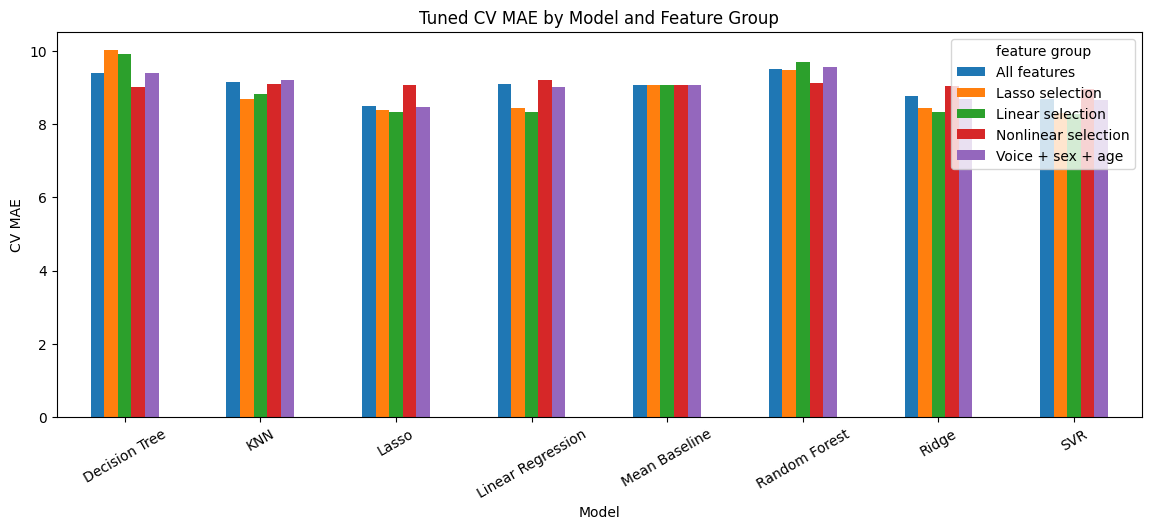

In [107]:
cv_chart = comparison.pivot(index="model", columns="feature group", values="CV MAE")
cv_chart.plot(kind="bar", figsize=(14, 5))
plt.xlabel("Model")
plt.ylabel("CV MAE")
plt.title("Tuned CV MAE by Model and Feature Group")
plt.xticks(rotation=30)
plt.show()

### Train vs CV MAE

A big gap between the two bars means the model is overfitting.

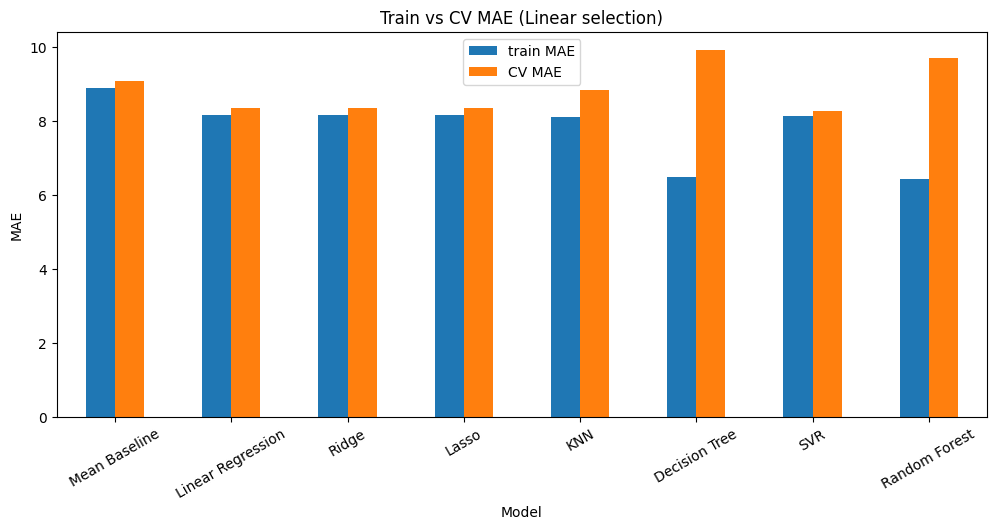

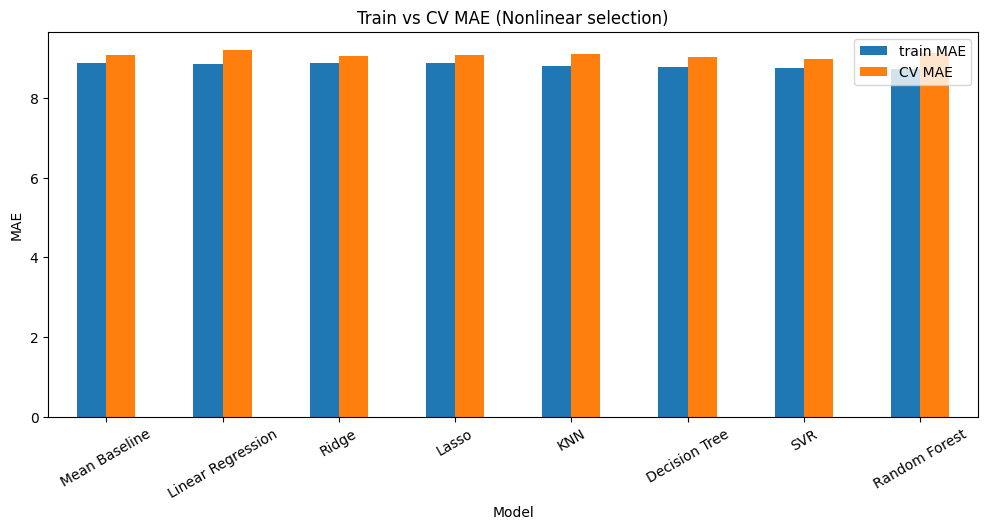

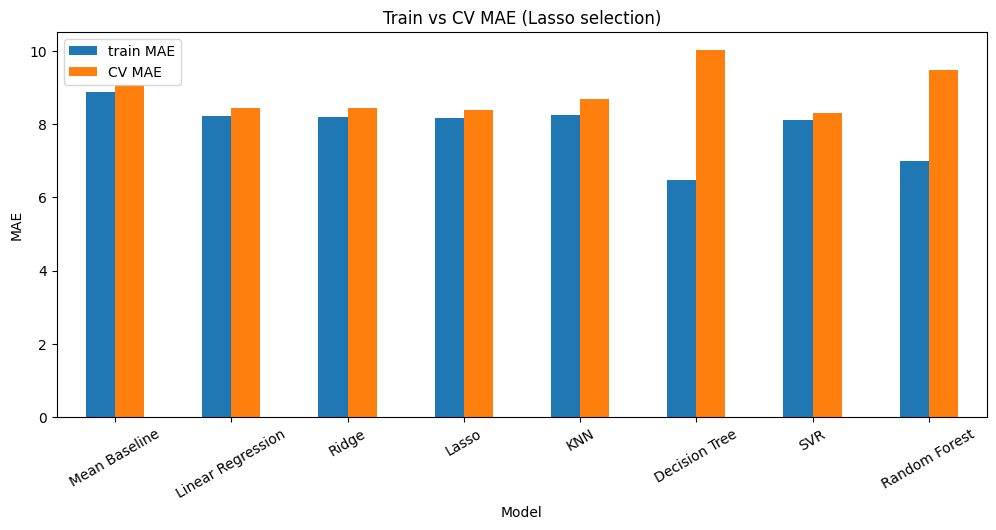

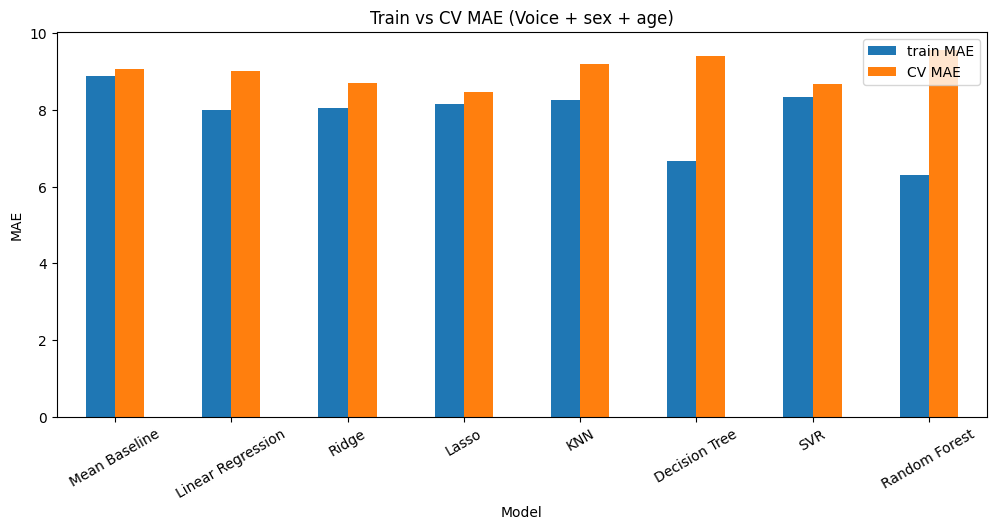

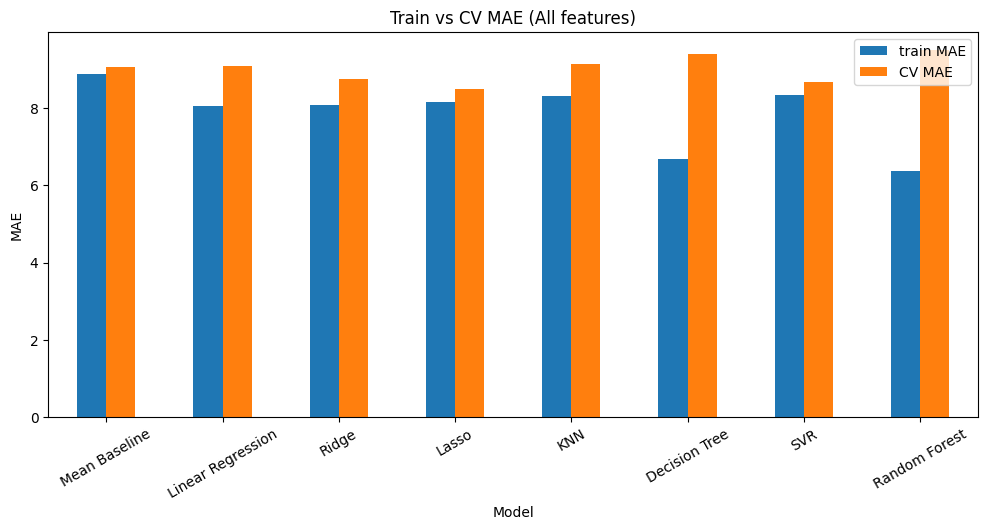

In [108]:
for group in feature_groups:
    group_table = comparison[comparison["feature group"] == group].set_index("model")
    group_table[["train MAE", "CV MAE"]].plot(kind="bar", figsize=(12, 5))
    plt.xlabel("Model")
    plt.ylabel("MAE")
    plt.title(f"Train vs CV MAE ({group})")
    plt.xticks(rotation=30)
    plt.show()

## Final Test Evaluation (TODO)

**Placeholder.** Pick the final model and feature group from the comparison above, then evaluate it once on `X_test` and `y_test`.

In [109]:
# TODO: final test evaluation goes here